# Exploratory Data Analysis - Retailrocket Dataset

**Goal:** Understand the structure, quality, and patterns in the Retailrocket e-commerce dataset before building the Apriori recommendation model.

**Dataset source:** [Retailrocket Recommender System Dataset (Kaggle)](https://www.kaggle.com/datasets/retailrocket/ecommerce-dataset)

**Files:**
- `events.csv` - user interaction logs (view, addtocart, transaction)
- `category_tree.csv` - category hierarchy
- `item_properties_part1.csv` / `item_properties_part2.csv` - item attributes over time

## 1. Imports and Configuration

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100

# Path to raw data (relative to notebook location)
RAW_DATA_PATH = '../../data/raw'

## 2. Loading the Data

In [6]:
# --- Events ---
# Each row = one user interaction with a product
# Columns: timestamp (ms), visitorid, event type, itemid, transactionid (only for purchases)
events = pd.read_csv(f'{RAW_DATA_PATH}/events.csv')

print(f'Events loaded: {len(events):,} rows')
events.head()

Events loaded: 2,756,101 rows


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [7]:
# --- Category Tree ---
# Hierarchical structure: each category has a parent category
categories = pd.read_csv(f'{RAW_DATA_PATH}/category_tree.csv')

print(f'Categories loaded: {len(categories):,} rows')
categories.head()

Categories loaded: 1,669 rows


,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0


In [8]:
# --- Item Properties ---
# Item attributes that change over time (e.g., categoryid, price, availability)
# We load both parts and concatenate them
item_props_1 = pd.read_csv(f'{RAW_DATA_PATH}/item_properties_part1.csv')
item_props_2 = pd.read_csv(f'{RAW_DATA_PATH}/item_properties_part2.csv')
item_properties = pd.concat([item_props_1, item_props_2], ignore_index=True)

# Free memory - individual parts are no longer needed
del item_props_1, item_props_2

print(f'Item properties loaded: {len(item_properties):,} rows')
item_properties.head()

Item properties loaded: 20,275,902 rows


,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513


## 3. Data Overview — Structure and Quality

In [9]:
print('=== EVENTS ===')
print(f'Shape: {events.shape}')
print(f'\nData types:\n{events.dtypes}')
print(f'\nMissing values:\n{events.isnull().sum()}')
print(f'\nBasic stats:\n{events.describe()}')

=== EVENTS ===
Shape: (2756101, 5)

Data types:
timestamp          int64
visitorid          int64
event                str
itemid             int64
transactionid    float64
dtype: object

Missing values:
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

Basic stats:
          timestamp     visitorid        itemid  transactionid
count  2.756101e+06  2.756101e+06  2.756101e+06   22457.000000
mean   1.436424e+12  7.019229e+05  2.349225e+05    8826.497796
std    3.366312e+09  4.056875e+05  1.341954e+05    5098.996290
min    1.430622e+12  0.000000e+00  3.000000e+00       0.000000
25%    1.433478e+12  3.505660e+05  1.181200e+05    4411.000000
50%    1.436453e+12  7.020600e+05  2.360670e+05    8813.000000
75%    1.439225e+12  1.053437e+06  3.507150e+05   13224.000000
max    1.442545e+12  1.407579e+06  4.668670e+05   17671.000000


In [10]:
print('=== CATEGORIES ===')
print(f'Shape: {categories.shape}')
print(f'\nMissing values:\n{categories.isnull().sum()}')
print(f'\nCategories without a parent (root): {categories["parentid"].isnull().sum()}')

=== CATEGORIES ===
Shape: (1669, 2)

Missing values:
categoryid     0
parentid      25
dtype: int64

Categories without a parent (root): 25


In [11]:
print('=== ITEM PROPERTIES ===')
print(f'Shape: {item_properties.shape}')
print(f'\nUnique properties: {item_properties["property"].nunique()}')
print(f'\nTop 15 property types:\n{item_properties["property"].value_counts().head(15)}')

=== ITEM PROPERTIES ===
Shape: (20275902, 4)

Unique properties: 1104

Top 15 property types:
property
888           3000398
790           1790516
available     1503639
categoryid     788214
6              631471
283            597419
776            574220
678            481966
364            476486
202            448938
839            417239
917            417227
159            417053
764            417053
112            417053
Name: count, dtype: int64


## 4. Events Analysis

This is the **most important dataset** for our Apriori algorithm - we need transaction events to build market baskets.

### 4.1. Event Type Distribution

               Count  Percentage (%)
event                               
view         2664312           96.67
addtocart      69332            2.52
transaction    22457            0.81


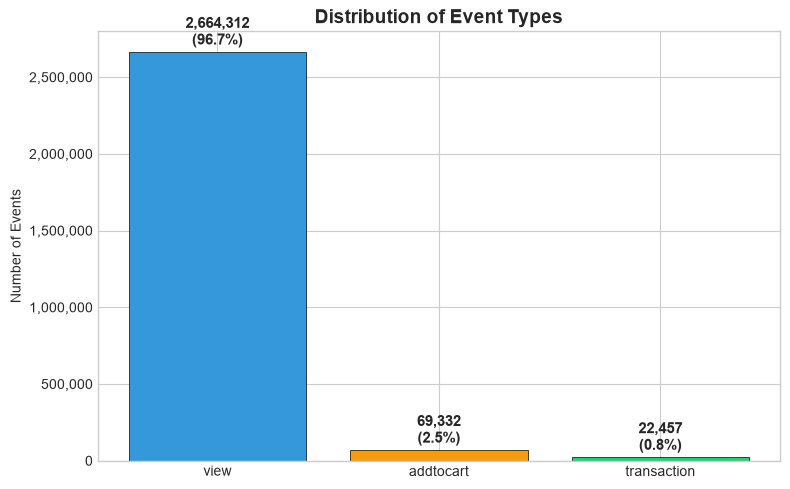

In [12]:
event_counts = events['event'].value_counts()
event_pct = events['event'].value_counts(normalize=True) * 100

# Summary table
event_summary = pd.DataFrame({
    'Count': event_counts,
    'Percentage (%)': event_pct.round(2)
})
print(event_summary)

# Bar chart
colors = {'view': '#3498db', 'addtocart': '#f39c12', 'transaction': '#2ecc71'}
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(event_counts.index, event_counts.values,
              color=[colors[e] for e in event_counts.index], edgecolor='black', linewidth=0.5)

# Add value labels on bars
for bar, pct in zip(bars, event_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 20000,
            f'{bar.get_height():,.0f}\n({pct:.1f}%)',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title('Distribution of Event Types', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Events')
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()

### 4.2. Conversion Funnel

The funnel shows how many users progress from viewing → adding to cart → completing a purchase. This is a standard e-commerce metric.

      Stage  Unique Visitors  Conversion Rate (%)
       View          1404179               100.00
Add to Cart            37722                 2.69
Transaction            11719                 0.83


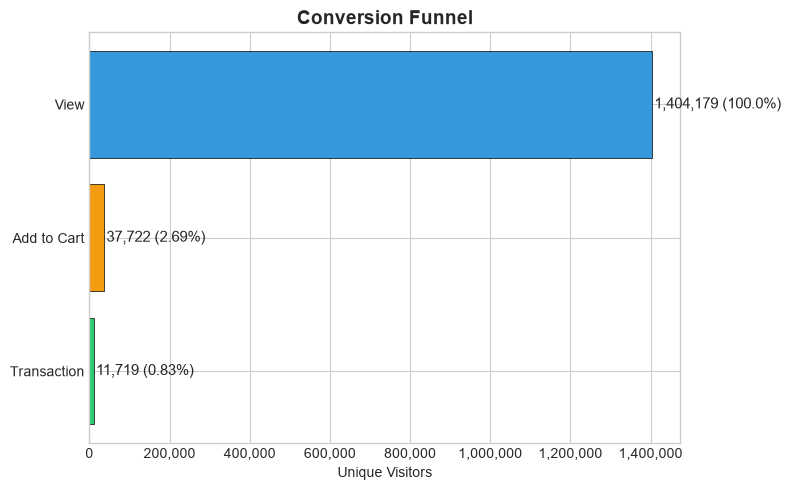

In [13]:
# How many UNIQUE visitors performed each event type?
visitors_view = events[events['event'] == 'view']['visitorid'].nunique()
visitors_cart = events[events['event'] == 'addtocart']['visitorid'].nunique()
visitors_buy  = events[events['event'] == 'transaction']['visitorid'].nunique()

funnel = pd.DataFrame({
    'Stage': ['View', 'Add to Cart', 'Transaction'],
    'Unique Visitors': [visitors_view, visitors_cart, visitors_buy],
})
funnel['Conversion Rate (%)'] = (funnel['Unique Visitors'] / visitors_view * 100).round(2)
print(funnel.to_string(index=False))

# Funnel chart
fig, ax = plt.subplots(figsize=(8, 5))
bar_colors = ['#3498db', '#f39c12', '#2ecc71']
bars = ax.barh(funnel['Stage'][::-1], funnel['Unique Visitors'][::-1],
               color=bar_colors[::-1], edgecolor='black', linewidth=0.5)

for bar, val, pct in zip(bars, funnel['Unique Visitors'][::-1], funnel['Conversion Rate (%)'][::-1]):
    ax.text(bar.get_width() + 5000, bar.get_y() + bar.get_height() / 2,
            f'{val:,} ({pct}%)', va='center', fontsize=11)

ax.set_title('Conversion Funnel', fontsize=14, fontweight='bold')
ax.set_xlabel('Unique Visitors')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()

### 4.3. Time Analysis

The `timestamp` column is in milliseconds (Unix epoch). Let's convert it to a proper datetime and see the data's time range.

In [14]:
# Convert timestamp from milliseconds to datetime
events['datetime'] = pd.to_datetime(events['timestamp'], unit='ms')
events['date'] = events['datetime'].dt.date
events['hour'] = events['datetime'].dt.hour
events['dayofweek'] = events['datetime'].dt.day_name()

print(f'Date range: {events["datetime"].min()} → {events["datetime"].max()}')
print(f'Total days: {(events["datetime"].max() - events["datetime"].min()).days}')

Date range: 2015-05-03 03:00:04.384000 → 2015-09-18 02:59:47.788000
Total days: 137


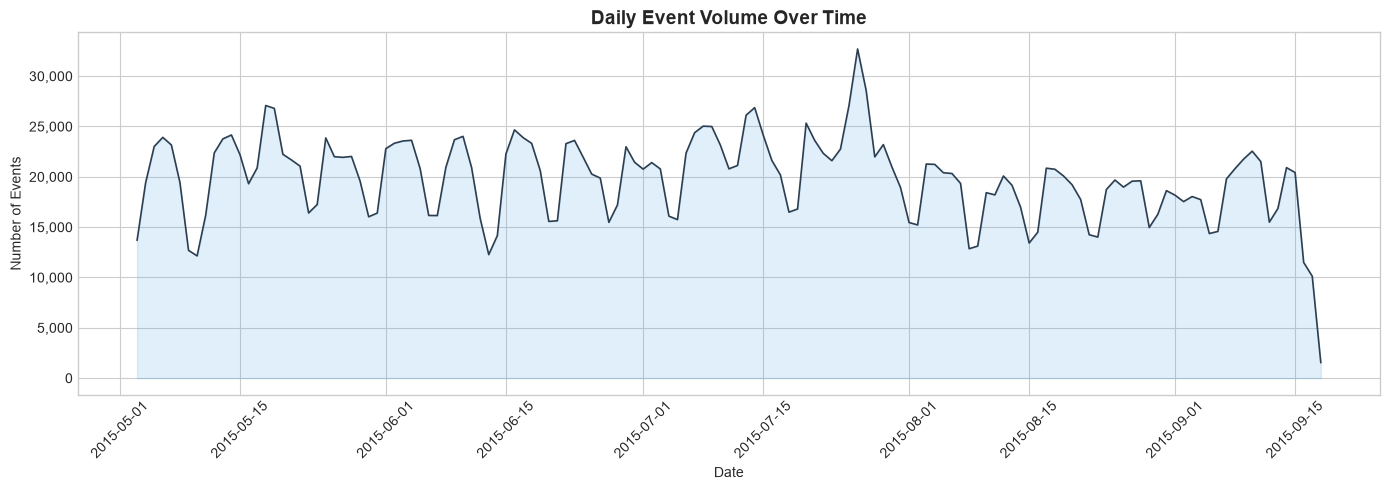

In [15]:
# Daily event volume
daily_events = events.groupby('date').size()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_events.index, daily_events.values, color='#2c3e50', linewidth=1.2)
ax.fill_between(daily_events.index, daily_events.values, alpha=0.15, color='#3498db')
ax.set_title('Daily Event Volume Over Time', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Events')
ax.set_xlabel('Date')
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

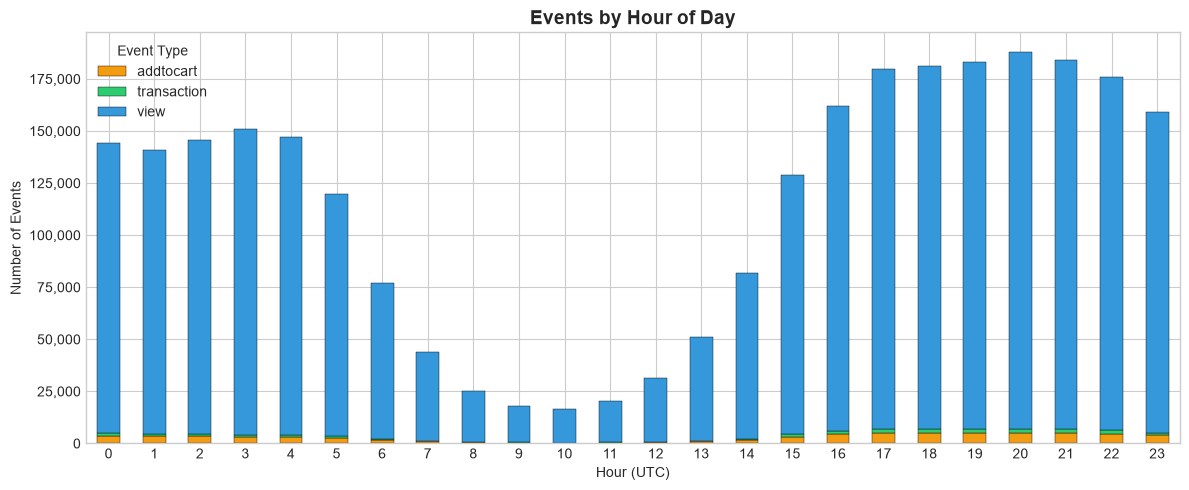

In [16]:
# Events by hour of day - when are users most active?
hourly = events.groupby(['hour', 'event']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(12, 5))
hourly.plot(kind='bar', stacked=True, ax=ax,
            color=['#f39c12', '#2ecc71', '#3498db'], edgecolor='black', linewidth=0.3)
ax.set_title('Events by Hour of Day', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Events')
ax.set_xlabel('Hour (UTC)')
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.legend(title='Event Type')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 4.4. Visitor Behavior

In [17]:
total_visitors = events['visitorid'].nunique()
total_items = events['itemid'].nunique()

print(f'Total unique visitors:  {total_visitors:,}')
print(f'Total unique items:     {total_items:,}')
print(f'Avg events per visitor: {len(events) / total_visitors:.1f}')

Total unique visitors:  1,407,580
Total unique items:     235,061
Avg events per visitor: 2.0



Events per visitor statistics:
count    1407580.0
mean           2.0
std           12.6
min            1.0
25%            1.0
50%            1.0
75%            2.0
max         7757.0
dtype: float64


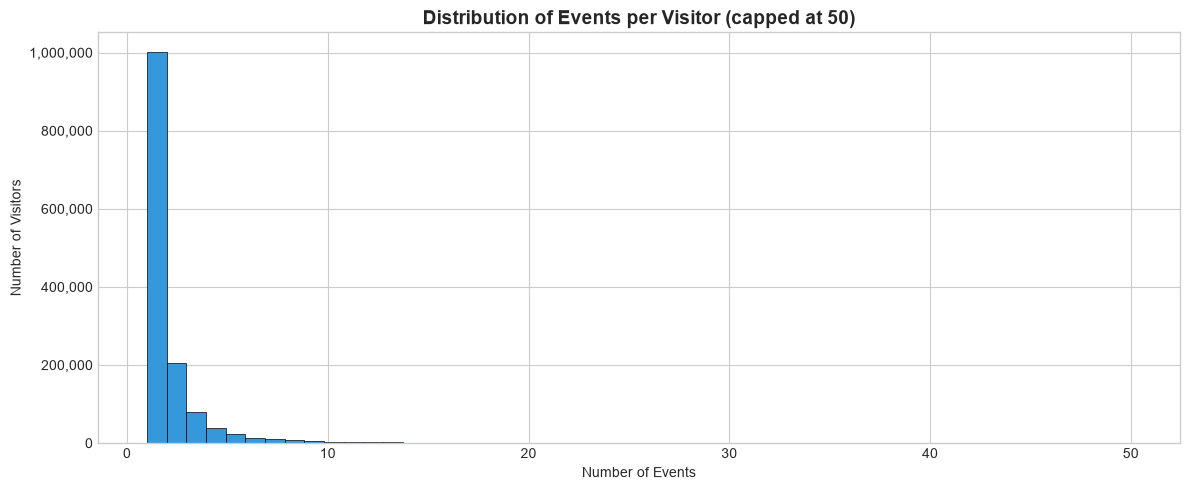

In [18]:
# Distribution of events per visitor
events_per_visitor = events.groupby('visitorid').size()

print(f'\nEvents per visitor statistics:')
print(events_per_visitor.describe().round(1))

# Histogram (capped at 50 to make it readable - heavy right tail expected)
fig, ax = plt.subplots(figsize=(12, 5))
events_per_visitor.clip(upper=50).hist(bins=50, ax=ax, color='#3498db',
                                       edgecolor='black', linewidth=0.5)
ax.set_title('Distribution of Events per Visitor (capped at 50)', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Events')
ax.set_ylabel('Number of Visitors')
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()

## 5. Transaction Analysis (Key for Apriori)

**This section is the most critical for our project.** The Apriori algorithm works on transaction data — sets of items bought together. We need to understand:
- How many transactions exist?
- How many items per transaction? (basket size)
- Which items are most frequently purchased?

In [19]:
# Filter only purchase events
transactions = events[events['event'] == 'transaction'].copy()

print(f'Total purchase events: {len(transactions):,}')
print(f'Unique transactions:   {transactions["transactionid"].nunique():,}')
print(f'Unique buyers:         {transactions["visitorid"].nunique():,}')
print(f'Unique items bought:   {transactions["itemid"].nunique():,}')

Total purchase events: 22,457
Unique transactions:   17,672
Unique buyers:         11,719
Unique items bought:   12,025


In [20]:
# Basket size = number of unique items per transaction
basket_sizes = transactions.groupby('transactionid')['itemid'].nunique()

print('Basket size statistics:')
print(basket_sizes.describe().round(1))
print(f'\nTransactions with 1 item:   {(basket_sizes == 1).sum():,} ({(basket_sizes == 1).mean() * 100:.1f}%)')
print(f'Transactions with 2+ items: {(basket_sizes >= 2).sum():,} ({(basket_sizes >= 2).mean() * 100:.1f}%)')

Basket size statistics:
count    17672.0
mean         1.3
std          0.9
min          1.0
25%          1.0
50%          1.0
75%          1.0
max         31.0
Name: itemid, dtype: float64

Transactions with 1 item:   15,029 (85.0%)
Transactions with 2+ items: 2,643 (15.0%)


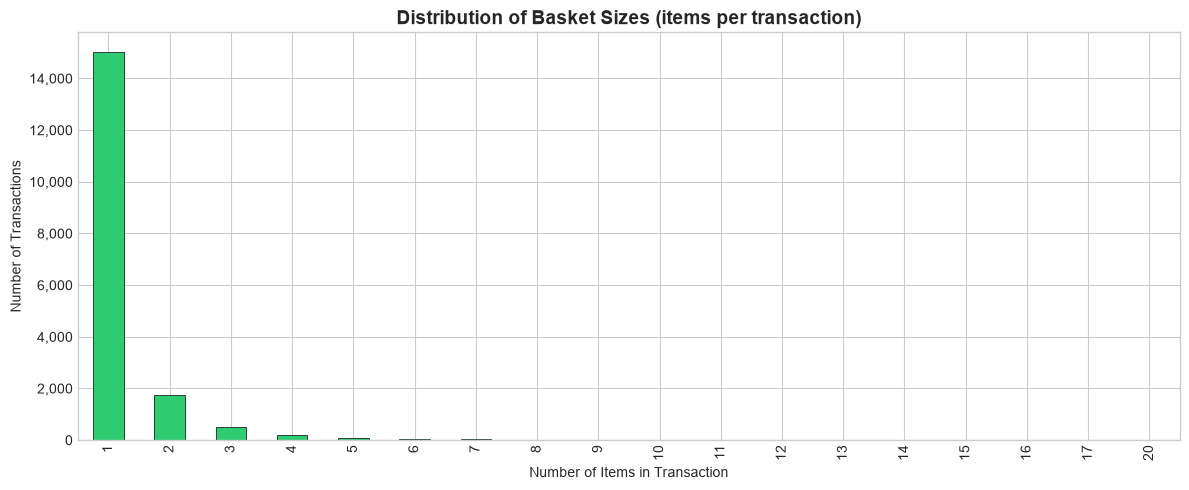

In [21]:
# Basket size distribution
fig, ax = plt.subplots(figsize=(12, 5))
basket_sizes.clip(upper=20).value_counts().sort_index().plot(
    kind='bar', ax=ax, color='#2ecc71', edgecolor='black', linewidth=0.5)

ax.set_title('Distribution of Basket Sizes (items per transaction)', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Items in Transaction')
ax.set_ylabel('Number of Transactions')
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()

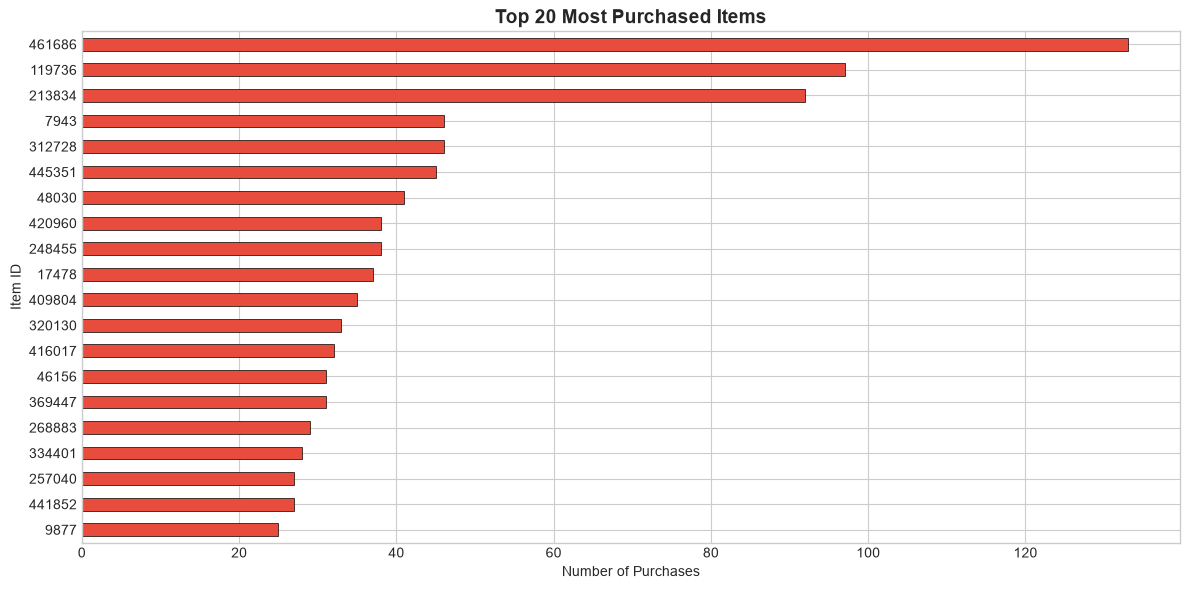

In [22]:
# Top 20 most purchased items
top_items = transactions['itemid'].value_counts().head(20)

fig, ax = plt.subplots(figsize=(12, 6))
top_items.plot(kind='barh', ax=ax, color='#e74c3c', edgecolor='black', linewidth=0.5)
ax.set_title('Top 20 Most Purchased Items', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Purchases')
ax.set_ylabel('Item ID')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 6. Category Analysis

In [23]:
print(f'Total categories: {len(categories):,}')
print(f'Root categories (no parent): {categories["parentid"].isnull().sum()}')

# Depth analysis - how deep is the category tree?
# A root category has parentid = NaN, its children have depth 1, etc.
cat_dict = dict(zip(categories['categoryid'], categories['parentid']))

def get_depth(cat_id):
    """Calculate the depth of a category in the hierarchy."""
    depth = 0
    current = cat_id
    visited = set()  # prevent infinite loops from circular references
    while pd.notna(cat_dict.get(current)) and current not in visited:
        visited.add(current)
        current = cat_dict[current]
        depth += 1
    return depth

categories['depth'] = categories['categoryid'].apply(get_depth)

print(f'\nCategory depth distribution:')
print(categories['depth'].value_counts().sort_index())

Total categories: 1,669
Root categories (no parent): 25

Category depth distribution:
depth
0     25
1    174
2    702
3    665
4     90
5     13
Name: count, dtype: int64


## 7. Item-Category Mapping from Properties

Items with category mapping: 417,053


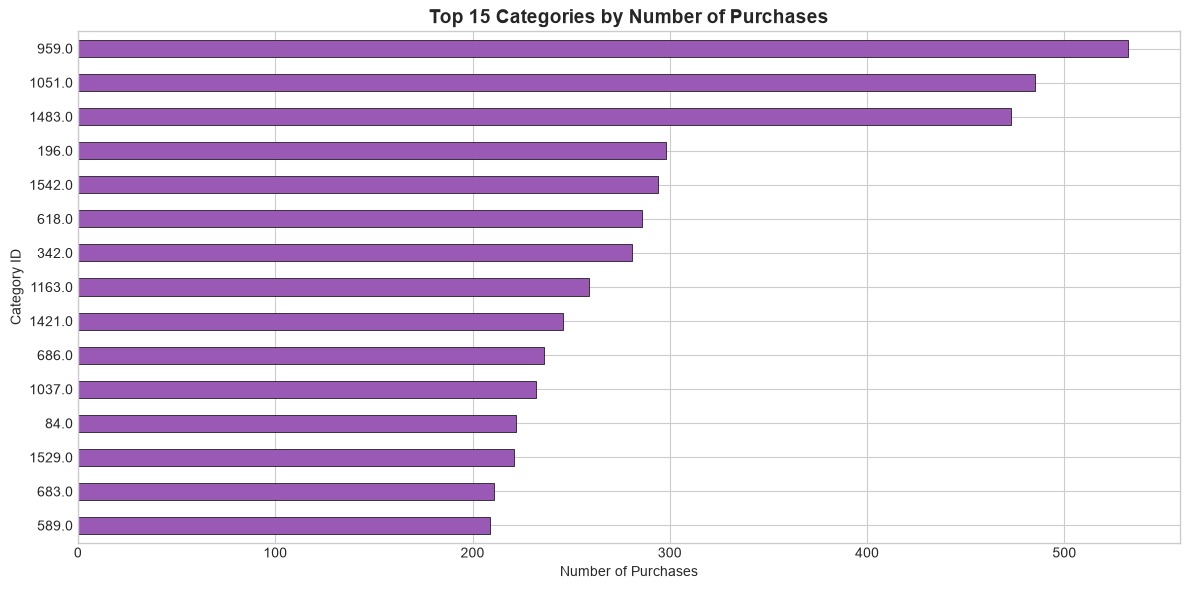

In [24]:
# Extract category assignments from item_properties
# The property 'categoryid' maps items to categories
item_categories = item_properties[item_properties['property'] == 'categoryid'][['itemid', 'value']].copy()
item_categories.columns = ['itemid', 'categoryid']
item_categories['categoryid'] = pd.to_numeric(item_categories['categoryid'], errors='coerce')

# Take the latest category assignment per item (drop duplicates, keep last)
item_categories = item_categories.drop_duplicates(subset='itemid', keep='last')

print(f'Items with category mapping: {len(item_categories):,}')

# Merge with transactions to see top categories by purchases
trans_with_cat = transactions.merge(item_categories, on='itemid', how='left')
top_cats = trans_with_cat['categoryid'].value_counts().head(15)

fig, ax = plt.subplots(figsize=(12, 6))
top_cats.plot(kind='barh', ax=ax, color='#9b59b6', edgecolor='black', linewidth=0.5)
ax.set_title('Top 15 Categories by Number of Purchases', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Purchases')
ax.set_ylabel('Category ID')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 8. "Add to Cart" vs Actual Purchases

In [25]:
# How often does adding to cart lead to a purchase?
cart_visitors = set(events[events['event'] == 'addtocart']['visitorid'])
buy_visitors  = set(events[events['event'] == 'transaction']['visitorid'])

cart_to_buy = cart_visitors & buy_visitors  # visitors who did both

print(f'Visitors who added to cart:      {len(cart_visitors):,}')
print(f'Visitors who completed purchase:  {len(buy_visitors):,}')
print(f'Cart → Purchase conversion:       {len(cart_to_buy):,} ({len(cart_to_buy)/len(cart_visitors)*100:.1f}%)')
print(f'Cart abandonment rate:            {(1 - len(cart_to_buy)/len(cart_visitors))*100:.1f}%')

Visitors who added to cart:      37,722
Visitors who completed purchase:  11,719
Cart → Purchase conversion:       10,576 (28.0%)
Cart abandonment rate:            72.0%


## 9. Key Findings Summary

Document the key insights below after running the notebook. These findings will inform the Apriori model configuration.

**Findings to fill in after execution:**

| Metric | Value |
| :--- | :--- |
| Total events |2 756 101 |
| Date range |2015-05-03 → 2015-09-18 (137 days) |
| Unique visitors |1 407 580 |
| Unique items |235 061 |
| Total transactions |17 672 |
| Avg basket size |1.3 |
| % single-item baskets |85% |
| View → Purchase conversion |0.83% |
| Cart abandonment rate |72% |

**Implications for Apriori:**
- If most baskets have only 1 item, we may need to also consider "addtocart" events or session-based baskets (items viewed in the same session) alongside actual transactions.
- The `min_support` threshold must be set very low if the item space is large and transactions are sparse.
- Popular items will dominate association rules — we may need to filter or weight by `lift` to find non-trivial recommendations.